# 이진 분류 · 고객 이탈 실전 연습

공개 응시 후기의 작업 유형을 바탕으로 만든 **창작 14문항**입니다. 실제 기출 원문이 아닙니다. 문제에 지정한 변수명·조건을 지키세요. 각 문제의 설명은 필요한 용도를, 접힌 힌트는 함수 이름을 알려줍니다. 정답은 별도 파일입니다.

학습/검증 **2분할**을 사용합니다. 13~14번은 딥러닝 집중 문제입니다. 기준 모델 비교 등 추가 이해용 문항은 없습니다.

정답 churn: 0=유지, 1=이탈. age=나이, tenure_months=가입 개월, wait_minutes=대기 분, satisfaction=만족도, plan=요금제, past_tickets=문의 횟수.

## 01. 라이브러리

데이터 처리와 그래프 작성에 사용할 pandas, NumPy, matplotlib.pyplot, seaborn을 각각 pd, np, plt, sns로 불러오세요.

<details><summary>힌트 보기</summary>

import … as …

</details>

In [36]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 02. 데이터 읽기

`01_churn.csv`를 읽어 data에 저장하고 처음 5행을 출력하세요.

<details><summary>힌트 보기</summary>

pd.read_csv()

</details>

In [37]:
# 여기에 답안코드를 작성하고 실행하세요.
data = pd.read_csv("01_churn.csv")
data.head(5)

,age,tenure_months,wait_minutes,satisfaction,plan,past_tickets,churn
0,31,3,2.86,3.53,Basic,0,0
1,38,16,15.19,1.42,Plus,1,0
2,42,15,8.47,2.07,Plus,4,1
3,33,2,20.95,1.56,Premium,3,1
4,68,84,14.90,1.09,Plus,1,1


## 03. 데이터 확인

행·열 개수, 자료형, 컬럼별 결측치 수를 확인하세요. 결측치가 가장 많은 컬럼 이름을 answer03에 저장하세요.

<details><summary>힌트 보기</summary>

shape, info(), isnull().sum(), idxmax()

</details>

In [53]:
# 여기에 답안코드를 작성하고 실행하세요.
print(data.shape)
print(data.info())
print(data.isnull().sum())

answer03 = "wait_minutes"

(1000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            1000 non-null   int64  
 1   tenure_months  1000 non-null   int64  
 2   wait_minutes   1000 non-null   float64
 3   satisfaction   1000 non-null   float64
 4   plan           1000 non-null   str    
 5   past_tickets   1000 non-null   int64  
 6   churn          1000 non-null   int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 54.8 KB
None
age              0
tenure_months    0
wait_minutes     0
satisfaction     0
plan             0
past_tickets     0
churn            0
dtype: int64


## 04. 그룹별 집계

`plan`별 `churn`의 평균을 계산해 group_result에 저장하고 출력하세요. 그룹 간 차이를 확인하는 작업입니다.

<details><summary>힌트 보기</summary>

groupby()[…].mean()

</details>

In [39]:
# 여기에 답안코드를 작성하고 실행하세요.
group_result = data.groupby("plan")["churn"].mean()
group_result

plan
Basic      0.675057
Plus       0.569801
Premium    0.634518
Name: churn, dtype: float64

## 05. 시각화

seaborn countplot으로 churn별 표본 수를 그리세요. 제목은 Churn Count입니다.

<details><summary>힌트 보기</summary>

sns.countplot / sns.scatterplot

</details>

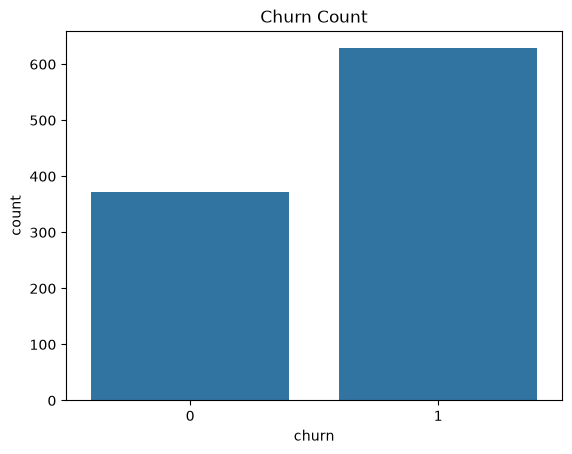

In [40]:
# 여기에 답안코드를 작성하고 실행하세요.

sns.countplot(data=data, x="churn")

plt.title("Churn Count")
plt.show()

## 06. 결측치 처리

`wait_minutes`의 결측치는 해당 컬럼 중앙값으로, `plan`의 결측치는 최빈값으로 대체하세요. 처리 결과를 data에 반영하고 결측치 수를 확인하세요.

<details><summary>힌트 보기</summary>

fillna(), median(), mode()[0]

</details>

In [41]:
# 여기에 답안코드를 작성하고 실행하세요.
data["wait_minutes"] = data["wait_minutes"].fillna(data["wait_minutes"].median())
data["plan"] = data["plan"].fillna(data["plan"].mode().iloc[0])

print(data.isna().sum())

age              0
tenure_months    0
wait_minutes     0
satisfaction     0
plan             0
past_tickets     0
churn            0
dtype: int64


## 07. 범주형 인코딩

`plan`을 pd.get_dummies로 변환해 data_encoded에 저장하세요. dtype=int로 설정하고 나머지 컬럼은 유지하세요.

<details><summary>힌트 보기</summary>

pd.get_dummies(data, columns=[…], dtype=int)

</details>

In [42]:
# 여기에 답안코드를 작성하고 실행하세요.
data_encoded = pd.get_dummies(
    data,
    columns=["plan"],
    dtype=int
)

data_encoded

,age,tenure_months,wait_minutes,satisfaction,past_tickets,churn,plan_Basic,plan_Plus,plan_Premium
0,31,3,2.86,3.53,0,0,1,0,0
1,38,16,15.19,1.42,1,0,0,1,0
2,42,15,8.47,2.07,4,1,0,1,0
3,33,2,20.95,1.56,3,1,0,0,1
4,68,84,14.90,1.09,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...
995,40,9,9.26,4.66,3,1,0,1,0
996,48,7,21.42,2.13,1,1,0,0,1
997,47,19,10.14,3.90,0,1,0,1,0
998,31,33,11.37,3.80,3,0,1,0,0


## 08. 입력과 정답 분리

data_encoded에서 `churn`을 제외한 입력을 X에, `churn`을 y에 저장하세요.

<details><summary>힌트 보기</summary>

drop(columns=[…])

</details>

In [43]:
# 여기에 답안코드를 작성하고 실행하세요.
X = data_encoded.drop(columns=["churn"])
y = data_encoded["churn"]

## 09. 학습·검증 분할

train_test_split으로 학습 80%, 검증 20%, random_state=42로 분할하세요. 변수는 X_train, X_valid, y_train, y_valid입니다. 클래스 비율을 유지하도록 stratify=y를 지정하세요.

<details><summary>힌트 보기</summary>

sklearn.model_selection.train_test_split

</details>

In [44]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 10. 스케일링

StandardScaler를 scaler에 생성하세요. 학습 입력은 fit_transform하여 X_train_scaled에, 검증 입력은 transform하여 X_valid_scaled에 저장하세요.

<details><summary>힌트 보기</summary>

sklearn.preprocessing.StandardScaler

</details>

In [45]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

## 11. 머신러닝 학습

RandomForestClassifier를 rf에 생성하세요. n_estimators=100, max_depth=6, random_state=42로 설정하고 X_train, y_train으로 학습하세요. X_valid 예측을 pred_rf에 저장하세요.

<details><summary>힌트 보기</summary>

sklearn.ensemble

</details>

In [46]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.ensemble import RandomForestClassifier 

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    random_state=42
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_valid)

## 12. 머신러닝 평가

정확도와 재현율을 각각 acc_rf, recall_rf에 저장해 출력하세요. 둘 다 확률이 아닌 예측 클래스 pred_rf로 계산합니다.

<details><summary>힌트 보기</summary>

sklearn.metrics

</details>

In [ ]:
# 여기에 답안코드를 작성하고 실행하세요.
from sklearn.metrics import accuracy_score, recall_score

acc_rf = accuracy_score(y_valid, pred_rf)
recall_rf = recall_score(y_valid, pred_rf)

## 13. 딥러닝 구성·학습

다음 조건에 맞춰 model을 구성하고 학습하세요. Dense는 뉴런 층, Dropout은 학습 중 일부 출력을 꺼 과적합을 줄이는 층입니다.

- 입력 특성 수: X_train_scaled.shape[1]
- 은닉층: Dense(32, relu) → Dropout(0.2) → Dense(16, relu)
- 출력층: Dense(1, sigmoid)
- optimizer: adam, loss: binary_crossentropy, metrics: ["accuracy"]
- estop: EarlyStopping, monitor="val_loss", patience=5
- checkpoint: ModelCheckpoint, 경로="best_01_churn.keras", monitor="val_loss", save_best_only=True
- epochs=30, batch_size=32, 검증 데이터=(X_valid_scaled, y_valid), callbacks=[estop, checkpoint]
- 학습 기록은 history에 저장하세요. 학습 정답은 y_train입니다.

<details><summary>힌트 보기</summary>

tensorflow.keras.models.Sequential, layers.Dense/Dropout, callbacks.EarlyStopping/ModelCheckpoint. model.compile() 후 history = model.fit().

</details>

In [48]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

estop = EarlyStopping(
    monitor="val_loss",
    patience=5
)

checkpoint = ModelCheckpoint(
    filepath="best_01_churn.keras",
    monitor="val_loss",
    save_best_only=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_valid_scaled, y_valid),
    callbacks=[estop, checkpoint]
)


Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4725 - loss: 0.7088 - val_accuracy: 0.6750 - val_loss: 0.6605
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5913 - loss: 0.6721 - val_accuracy: 0.6600 - val_loss: 0.6384
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6350 - loss: 0.6459 - val_accuracy: 0.6600 - val_loss: 0.6213
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6662 - loss: 0.6230 - val_accuracy: 0.6800 - val_loss: 0.6049
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6875 - loss: 0.6020 - val_accuracy: 0.6800 - val_loss: 0.5888
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7075 - loss: 0.5734 - val_accuracy: 0.7000 - val_loss: 0.5725
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7100 - loss: 0.5664 - val_accuracy: 0.7100 - val_loss: 0.5623
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7100 - loss: 0.5560 - val_accuracy: 0.7250 - val_loss:

## 14. 저장 모델 예측·평가·그래프

① 다음 작업을 수행하세요.`best_01_churn.keras`를 load_model로 불러와 best_model에 저장하세요.

② X_valid_scaled 예측 전체를 dl_output에 저장하세요. 출력이 1열이므로 dl_output[:, 0]을 dl_proba에 저장하세요. 이 값은 클래스 1의 확률입니다. 0.5 이상이면 1, 미만이면 0으로 바꿔 dl_pred에 저장하세요. 정확도를 acc_dl에 저장해 출력하세요.

③ history의 accuracy와 val_accuracy를 한 그래프에 그리세요. 범례는 accuracy/val_accuracy, 제목은 Model Accuracy, x축은 Epoch, y축은 Accuracy입니다.

그래프는 이번 학습의 전체 기록이고, 예측은 저장된 최적 모델을 사용합니다.

<details><summary>힌트 보기</summary>

load_model(), predict(), [:, 0], (확률 >= 0.5).astype(int), history.history[지표명]

</details>

In [52]:
# 여기에 답안코드를 작성하고 실행하세요.
from tensorflow.keras.models import load_model
best_model = load_model("best_01_churn.keras")

dl_output = best_model.predict(X_valid_scaled)
dl_proba = dl_output[:,0]
dl_pred = (dl_proba>=0.5).astype(int)
acc_dl = accuracy_score(y_valid, dl_pred)

print(acc_dl)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
0.755


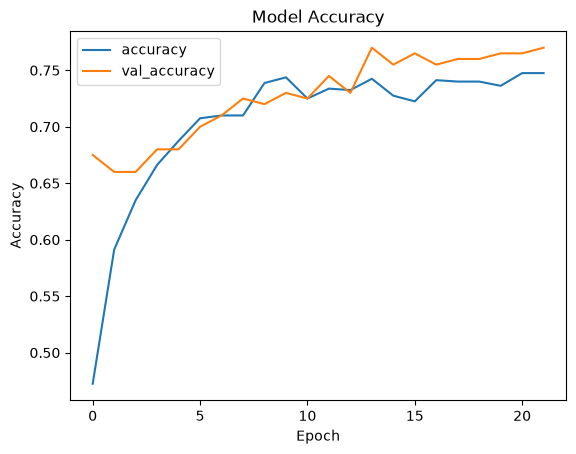

In [50]:
plt.plot(history.history["accuracy"], label="accuracy")
plt.plot(history.history["val_accuracy"], label="val_accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

참고: 시험 흐름에 맞춰 06~07번 전처리를 분할 전에 지시했습니다. 실무의 엄격한 성능 검증에서는 분할 후 학습 데이터에서 대체값과 인코딩 기준을 정하는 것이 원칙입니다. 이 세트는 시험형 코드 작성 연습입니다.

문항의 출처와 근거 수준은 READ_ME.md를 참고하세요.